# Financial consumer complaints in Colombia

**Objective:** analyse the complaints that consumers file against banks and insurers in Colombia: which products and reasons generate more complaints, how they evolve, and which entities have more complaints **relative to their size** (a big bank will always have more complaints in absolute numbers).

**Data (all from the Superintendencia Financiera, datos.gov.co):**
- Complaints received by supervised entities, by month, entity, product, reason and channel (`xyy7-rn7p`, 2023-2026)
- Bank assets from the CUIF financial statements (`mxk5-ce6w`)
- Insurance premiums by insurer from the Formato 290 (`e967-4a8r`)

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn` and `requests`.

## Part 1. Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
pd.set_option("display.max_colwidth", 70)

## Part 2. Download the complaints

The dataset has more than 1 million rows, so we let the API do the `GROUP BY` and we only download the totals we need.

In [2]:
def soql(dataset, params, nombre):
    ruta = f"data/{nombre}.csv"
    if os.path.exists(ruta):
        return pd.read_csv(ruta)
    url = f"https://www.datos.gov.co/resource/{dataset}.json"
    filas, offset = [], 0
    while True:
        r = requests.get(url, params={**params, "$limit": 50000, "$offset": offset}, timeout=600)
        pagina = r.json()
        filas.extend(pagina)
        if len(pagina) < 50000:
            break
        offset += 50000
    df = pd.DataFrame(filas)
    df.to_csv(ruta, index=False)
    return df

q = "sum(cantidad_quejas_recibidas) AS quejas"
mensual = soql("xyy7-rn7p", {"$select": f"a_o_creacion, mes_creacion, tipo_entidad, instancia_recepcion, {q}",
                             "$group": "a_o_creacion, mes_creacion, tipo_entidad, instancia_recepcion"}, "complaints_monthly")
producto = soql("xyy7-rn7p", {"$select": f"tipo_entidad, producto, motivo, {q}", "$where": "a_o_creacion = '2025'",
                              "$group": "tipo_entidad, producto, motivo"}, "complaints_2025_product_reason")
entidad = soql("xyy7-rn7p", {"$select": f"tipo_entidad, codigo_entidad, {q}", "$where": "a_o_creacion = '2025'",
                             "$group": "tipo_entidad, codigo_entidad"}, "complaints_2025_entity")
# the API gives everything as text, so we convert the numbers
for d in [mensual, producto, entidad]:
    d["quejas"] = pd.to_numeric(d["quejas"])
    d["tipo_entidad"] = d["tipo_entidad"].astype(int)
entidad["codigo_entidad"] = entidad["codigo_entidad"].astype(int)
print("Total complaints in the dataset:", mensual["quejas"].sum())

Total complaints in the dataset: 9784970


## Part 3. Evolution and channel

`tipo_entidad` 1 are banks, 13 general insurers and 14 life insurers.

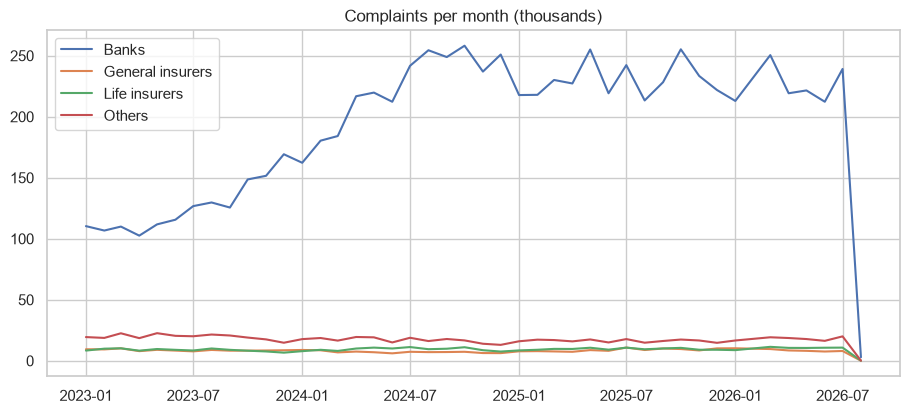

tipo,Banks,General insurers,Life insurers,Others
a_o_creacion,,,,
2023,1508243,104410,105404,235921
2024,2666499,86558,113770,203180
2025,2761458,105571,115699,196197
2026,1358322,52122,62827,108789


In [3]:
mensual["fecha"] = pd.to_datetime(mensual["a_o_creacion"].astype(str) + "-" + mensual["mes_creacion"].astype(str) + "-01")
tipos = {1: "Banks", 13: "General insurers", 14: "Life insurers"}
mensual["tipo"] = mensual["tipo_entidad"].map(tipos).fillna("Others")
serie = mensual.groupby(["fecha", "tipo"])["quejas"].sum().unstack()

plt.figure(figsize=(11, 4.5))
for c in serie.columns:
    plt.plot(serie.index, serie[c] / 1000, label=c)
plt.title("Complaints per month (thousands)")
plt.legend()
plt.savefig("figures/complaints_monthly.png", bbox_inches="tight")
plt.show()

anual = mensual.groupby(["a_o_creacion", "tipo"])["quejas"].sum().unstack()
anual

2026 has data only until August. Banks receive the big majority of the complaints. Note that 2023 looks lower because the new reporting format started in that year.

In [4]:
canal = mensual.groupby("instancia_recepcion")["quejas"].sum().sort_values(ascending=False)
(canal / canal.sum() * 100).round(1)

instancia_recepcion
Entidad vigilada                           87.8
Superintendencia Financiera de Colombia     6.4
Defensor del consumidor financiero          4.9
Otra (remisión por competencia)             0.9
Name: quejas, dtype: float64

More than 90% of the complaints are solved directly by the entity. Only a small part goes to the Superintendencia or to the "defensor del consumidor financiero".

## Part 4. Products and reasons (2025)

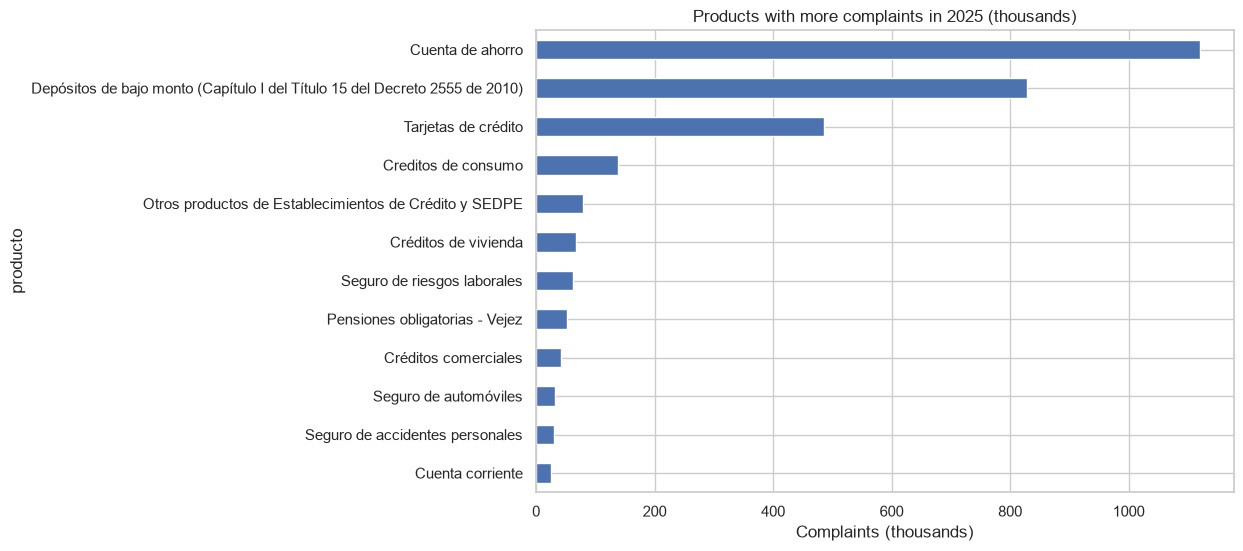

In [5]:
prod = producto.groupby("producto")["quejas"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 6))
(prod.head(12) / 1000).sort_values().plot.barh()
plt.title("Products with more complaints in 2025 (thousands)")
plt.xlabel("Complaints (thousands)")
plt.savefig("figures/products_2025.png", bbox_inches="tight")
plt.show()

In [6]:
# the main reasons inside the 3 products with more complaints
for p in prod.index[:3]:
    m = producto[producto["producto"] == p].groupby("motivo")["quejas"].sum().sort_values(ascending=False)
    print(p)
    print((m.head(5) / m.sum() * 100).round(1).to_string(), "\n")

Cuenta de ahorro
motivo
Transacción no reconocida                                 47.6
Cobro por operaciones fallidas en cajeros electrónicos     6.6
No disponibilidad o fallas de los canales de atención      5.8
Transacción mal aplicada                                   4.8
Información o asesoría incompleta y/o errada               4.4 

Depósitos de bajo monto (Capítulo I del Título 15 del Decreto 2555 de 2010)
motivo
Transacción no reconocida                                                                        25.7
Transacción mal aplicada                                                                         19.1
Dificultad o imposibilidad para realizar transacciones o consulta de información por el canal    18.0
Demora o no aplicación del pago                                                                   7.5
Fallas o inoportunidad en el proceso de vinculación                                               6.3 

Tarjetas de crédito
motivo
Transacción no reconocida            

In [7]:
# and the reasons in insurance products (general and life insurers)
seg = producto[producto["tipo_entidad"].isin([13, 14])]
print("Insurance products with more complaints:")
print(seg.groupby("producto")["quejas"].sum().sort_values(ascending=False).head(8).to_string(), "\n")
print("Main reasons in insurance:")
m = seg.groupby("motivo")["quejas"].sum().sort_values(ascending=False)
print((m.head(8) / m.sum() * 100).round(1).to_string())

Insurance products with more complaints:
producto
Seguro de riesgos laborales                            61988
Seguro de automóviles                                  30970
Seguro de accidentes personales                        29641
Seguro de salud                                        18227
Seguro Obligatorio de Accidentes de Tránsito (SOAT)    16909
Seguro de sustracción                                  13447
Seguro de vida grupo                                   11961
Seguro de vida individual                              10919 

Main reasons in insurance:
motivo
Error en la facturación o cobro no pactado                               13.1
Inconformidad con la definición, autorización, dictamen o diagnóstico     8.7
Vinculación no autorizada                                                 8.4
No disponibilidad o fallas de los canales de atención                     5.7
Inconformidad con el servicio prestado por el proveedor                   5.3
Demora en el pago de la indemnizació

## Part 5. Names and size of the entities

The complaints dataset only has the code of the entity. We take the names and the size from the other two datasets of the Superintendencia: total assets for banks (December 2025) and written premiums in 2025 for insurers.

In [8]:
bancos = soql("mxk5-ce6w", {"$select": "codigo_entidad, nombre_entidad, valor",
                            "$where": "tipo_entidad = '1' AND moneda = '0' AND cuenta = '100000' AND fecha_corte = '2025-12-31T00:00:00.000'"},
              "bank_assets_2025")
bancos["assets_trillion"] = pd.to_numeric(bancos["valor"]) / 1e12
bancos["tipo_entidad"] = 1
bancos["codigo_entidad"] = bancos["codigo_entidad"].astype(int)

aseg = soql("e967-4a8r", {"$select": "tipo_entidad, codigo_entidad, nombre_entidad, total",
                          "$where": "a_o = '2025' AND mes = '12' AND unidad_de_captura = '1' AND subcuenta = '5'"},
            "insurer_premiums_2025")
aseg["premiums_billion"] = pd.to_numeric(aseg["total"]) / 1e9
aseg["codigo_entidad"] = aseg["codigo_entidad"].str.split("-").str[1].astype(int)
aseg["tipo_entidad"] = aseg["tipo_entidad"].astype(int)
aseg["nombre_entidad"] = aseg["nombre_entidad"].str.replace(r"^\d+-\d+\s+", "", regex=True)

limpiar = lambda s: s.str.replace(r"\s+S\.\s?A\.?.*$|\s+S\.?A\.?$", "", regex=True).str.replace('"', "").str.title().str.strip()
bancos["nombre"] = limpiar(bancos["nombre_entidad"])
aseg["nombre"] = limpiar(aseg["nombre_entidad"])

## Part 6. Complaints relative to size

In [9]:
eb = entidad[entidad["tipo_entidad"] == 1].merge(bancos[["codigo_entidad", "nombre", "assets_trillion"]], on="codigo_entidad")
eb = eb[eb["assets_trillion"] > 2]                       # we leave out very small banks
eb["per_trillion_assets"] = eb["quejas"] / eb["assets_trillion"]
eb = eb.sort_values("per_trillion_assets", ascending=False)
print("Banks:", len(eb))
eb[["nombre", "quejas", "assets_trillion", "per_trillion_assets"]].round(1).head(25)

Banks: 25


,nombre,quejas,assets_trillion,per_trillion_assets
3,Bancolombia,1828491,266.1,6870.2
18,Banco Falabella,32863,6.5,5081.2
24,Banco Serfinanza,14333,3.0,4735.1
16,Banco Coomeva,20491,5.8,3524.2
10,Scotiabank Colpatria,97066,41.2,2353.7
17,Banco Finandina,8897,3.9,2256.7
9,Banco Davivienda,345351,153.4,2250.7
15,Banco W,4593,2.6,1788.4
8,Banco Caja Social,34935,25.4,1376.5
6,Bbva Colombia,137272,109.0,1259.6


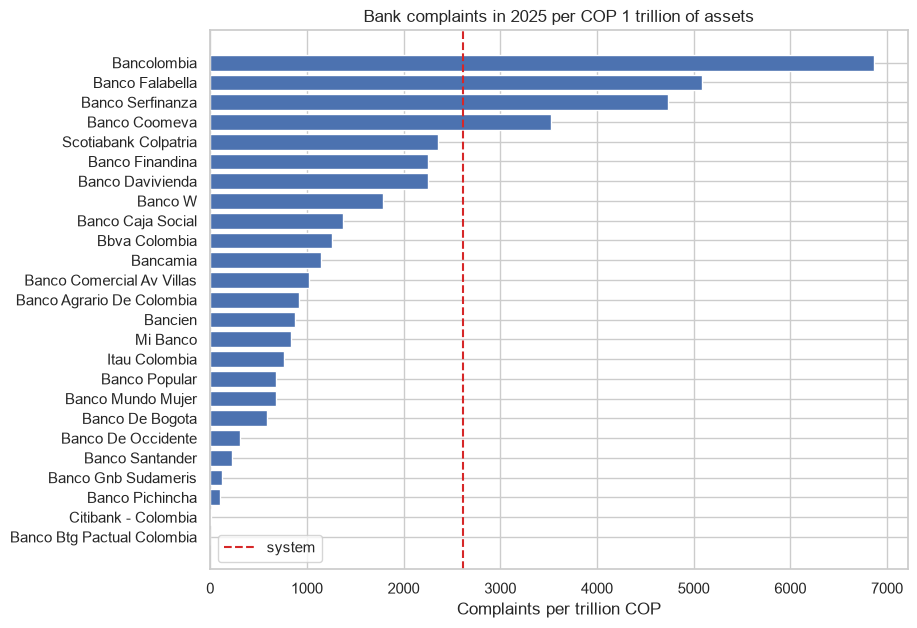

In [10]:
plt.figure(figsize=(9, 7))
plt.barh(eb["nombre"].iloc[::-1], eb["per_trillion_assets"].iloc[::-1])
plt.axvline(eb["quejas"].sum() / eb["assets_trillion"].sum(), color="tab:red", ls="--", label="system")
plt.title("Bank complaints in 2025 per COP 1 trillion of assets")
plt.xlabel("Complaints per trillion COP")
plt.legend()
plt.savefig("figures/banks_complaint_rate.png", bbox_inches="tight")
plt.show()

In [11]:
ea = entidad[entidad["tipo_entidad"].isin([13, 14])].merge(
    aseg[["tipo_entidad", "codigo_entidad", "nombre", "premiums_billion"]], on=["tipo_entidad", "codigo_entidad"])
ea = ea[ea["premiums_billion"] > 300]                    # insurers with more than COP 300.000 million in premiums
ea["per_billion_premiums"] = ea["quejas"] / ea["premiums_billion"]
ea["type"] = ea["tipo_entidad"].map({13: "general", 14: "life"})
ea = ea.sort_values("per_billion_premiums", ascending=False)
ea[["nombre", "type", "quejas", "premiums_billion", "per_billion_premiums"]].round(1).head(20)

,nombre,type,quejas,premiums_billion,per_billion_premiums
17,Cardif Colombia Seguros Generales,general,35059,1007.1,34.8
36,Bbva Seguros De Vida Colombia,life,8655,544.8,15.9
29,Metlife Colombia Seguros De Vida,life,6347,701.4,9.0
35,Riesgos Laborales Colmena O Arl Colmena O Colmena Riesgos Laborales,life,8676,993.0,8.7
15,Hdi Seguros,general,10611,1615.5,6.6
28,Seguros De Vida Sura,life,54442,9448.9,5.8
40,Colmena Seguros De Vida,life,2214,401.2,5.5
24,Axa Colpatria Seguros De Vida,life,9494,1735.5,5.5
10,Seguros Alfa,general,1917,416.4,4.6
7,Seguros Generales Sura,general,12916,3852.0,3.4


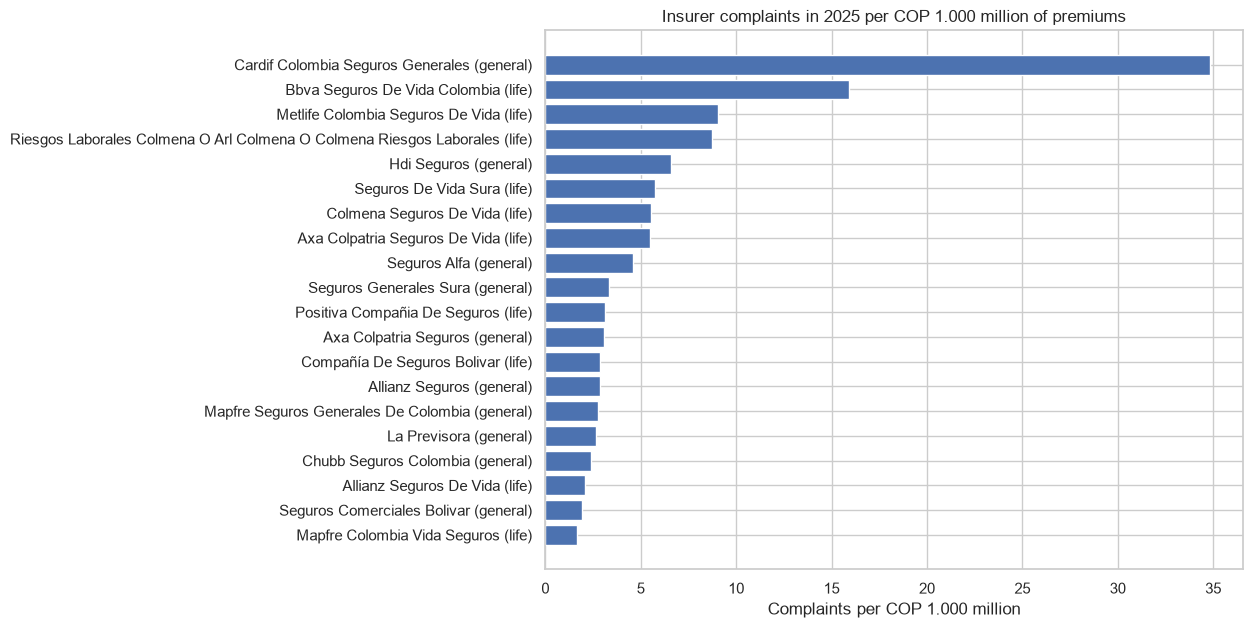

In [12]:
plt.figure(figsize=(9, 7))
top = ea.head(20).iloc[::-1]
plt.barh(top["nombre"] + " (" + top["type"] + ")", top["per_billion_premiums"])
plt.title("Insurer complaints in 2025 per COP 1.000 million of premiums")
plt.xlabel("Complaints per COP 1.000 million")
plt.savefig("figures/insurers_complaint_rate.png", bbox_inches="tight")
plt.show()

## Conclusions

- Savings accounts, low-amount deposits (digital wallets) and credit cards concentrate most of the complaints of the financial system. The main reasons are related to transactions that the client does not recognise (fraud) and to service problems.
- Bancolombia receives two thirds of all the bank complaints, and it is also first relative to its size: around 6.900 complaints per COP 1 trillion of assets, more than 2.5 times the system (around 2.600). After it come retail banks focused on consumer credit and cards like Falabella, Serfinanza and Coomeva.
- In insurance, the highest complaint rates are in companies linked to bank channels (bancassurance), like Cardif (35 complaints per COP 1.000 million of premiums, more than 10 times the median insurer) and BBVA Seguros de Vida. The main reasons are charges the client did not agree with and policies they did not know they had ("vinculación no autorizada"). For a broker this is useful: the complaint rate is one more criterion to choose with which insurer to place the policies of the clients.